### Importação dos dados



In [26]:
import pandas as pd

url = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_1.csv"
url2 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_2.csv"
url3 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_3.csv"
url4 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_4.csv"

loja = pd.read_csv(url)
loja2 = pd.read_csv(url2)
loja3 = pd.read_csv(url3)
loja4 = pd.read_csv(url4)

loja.head()

,Produto,Categoria do Produto,Preço,Frete,Data da Compra,Vendedor,Local da compra,Avaliação da compra,Tipo de pagamento,Quantidade de parcelas,lat,lon
0,Assistente virtual,eletronicos,219.08,9.249790,16/01/2021,Pedro Gomes,SP,4,cartao_credito,8,-22.19,-48.79
1,Mesa de jantar,moveis,256.35,11.234305,18/05/2022,Beatriz Moraes,RJ,1,cartao_credito,4,-22.25,-42.66
2,Jogo de tabuleiro,brinquedos,279.51,21.262681,15/03/2021,João Souza,DF,1,cartao_credito,1,-15.83,-47.86
3,Micro-ondas,eletrodomesticos,1009.99,54.667344,03/05/2022,João Souza,RS,4,boleto,1,-30.17,-53.50
4,Cadeira de escritório,moveis,446.99,26.964689,07/11/2020,Larissa Alves,MG,5,boleto,1,-18.10,-44.38


In [27]:
# A coluna 'Loja' é adicionada manualmente a cada DataFrame para identificar de qual loja vêm os dados.
loja['Loja'] = 'loja_1'
loja2['Loja'] = 'loja_2'
loja3['Loja'] = 'loja_3'
loja4['Loja'] = 'loja_4'

df = lojas_unidas = pd.concat([loja, loja2, loja3, loja4], ignore_index=True) # pd.concat() junta os quatro DataFrames em um único DataFrame chamado lojas_unidas.
df.head()
print(lojas_unidas.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9435 entries, 0 to 9434
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Produto                 9435 non-null   object 
 1   Categoria do Produto    9435 non-null   object 
 2   Preço                   9435 non-null   float64
 3   Frete                   9435 non-null   float64
 4   Data da Compra          9435 non-null   object 
 5   Vendedor                9435 non-null   object 
 6   Local da compra         9435 non-null   object 
 7   Avaliação da compra     9435 non-null   int64  
 8   Tipo de pagamento       9435 non-null   object 
 9   Quantidade de parcelas  9435 non-null   int64  
 10  lat                     9435 non-null   float64
 11  lon                     9435 non-null   float64
 12  Loja                    9435 non-null   object 
dtypes: float64(4), int64(2), object(7)
memory usage: 958.4+ KB
None


In [28]:
print(lojas_unidas.isnull().sum())

Produto                   0
Categoria do Produto      0
Preço                     0
Frete                     0
Data da Compra            0
Vendedor                  0
Local da compra           0
Avaliação da compra       0
Tipo de pagamento         0
Quantidade de parcelas    0
lat                       0
lon                       0
Loja                      0
dtype: int64


In [29]:
print(lojas_unidas.describe())

             Preço        Frete  Avaliação da compra  Quantidade de parcelas  \
count  9435.000000  9435.000000          9435.000000             9435.000000   
mean    622.309570    33.167002             4.014520                2.927398   
std     787.094508    41.973711             1.390518                2.802776   
min      10.070000     0.000000             1.000000                1.000000   
25%      73.610000     4.009423             3.000000                1.000000   
50%     295.350000    15.648481             5.000000                1.000000   
75%     884.405000    46.591030             5.000000                4.000000   
max    3969.380000   216.707633             5.000000               24.000000   

               lat          lon  
count  9435.000000  9435.000000  
mean    -20.534059   -47.171176  
std       5.399153     4.177887  
min     -30.170000   -70.550000  
25%     -22.250000   -48.790000  
50%     -22.190000   -48.790000  
75%     -18.100000   -44.380000  
max    

#1. Análise do faturamento



In [30]:
if 'Faturamento Total' not in lojas_unidas.columns: # Verifica se a coluna 'Faturamento Total' já existe; se não, cria somando Preço e Frete
    lojas_unidas['Faturamento Total'] = lojas_unidas['Preço'] + lojas_unidas['Frete']
faturamento_total_por_loja = lojas_unidas.groupby('Loja')['Faturamento Total'].sum() # Agrupa os dados por loja e calcula o faturamento total por loja
print("Faturamento Total por Loja:")
print(faturamento_total_por_loja)


Faturamento Total por Loja:
Loja
loja_1    1.616347e+06
loja_2    1.567773e+06
loja_3    1.542048e+06
loja_4    1.458253e+06
Name: Faturamento Total, dtype: float64


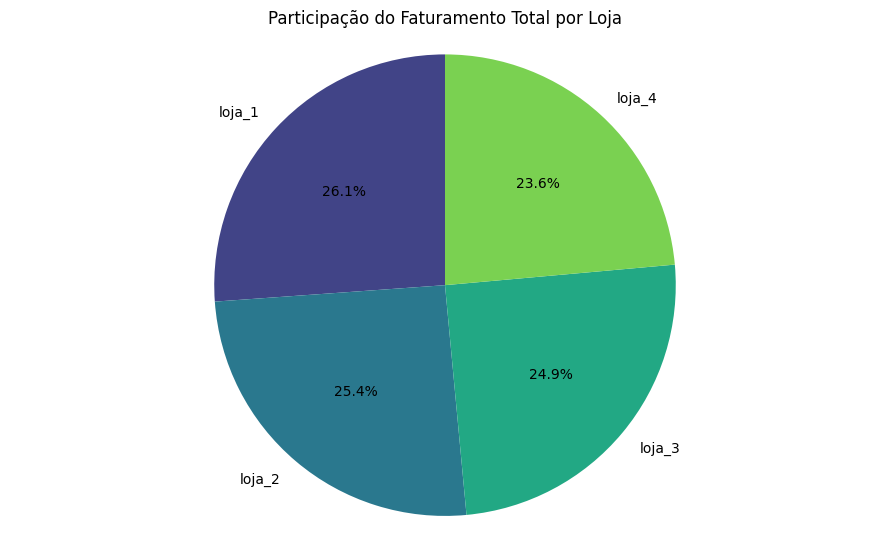

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5.6))
plt.pie(faturamento_total_por_loja.values,
        labels=faturamento_total_por_loja.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('viridis', len(faturamento_total_por_loja)))
plt.title('Participação do Faturamento Total por Loja')
plt.axis('equal') # Garante que o gráfico de pizza seja um círculo.
plt.tight_layout()
plt.show()

# 2. Vendas por Categoria

In [32]:
vendas_por_categoria = lojas_unidas.groupby('Categoria do Produto')['Preço'].sum().sort_values(ascending=False)
print("Vendas por Categoria:")
print(vendas_por_categoria)

Vendas por Categoria:
Categoria do Produto
eletronicos              2214099.72
eletrodomesticos         1766337.03
moveis                   1010214.00
instrumentos musicais     465029.67
esporte e lazer           190635.39
brinquedos                 98140.86
utilidades domesticas      76773.38
livros                     50260.74
Name: Preço, dtype: float64


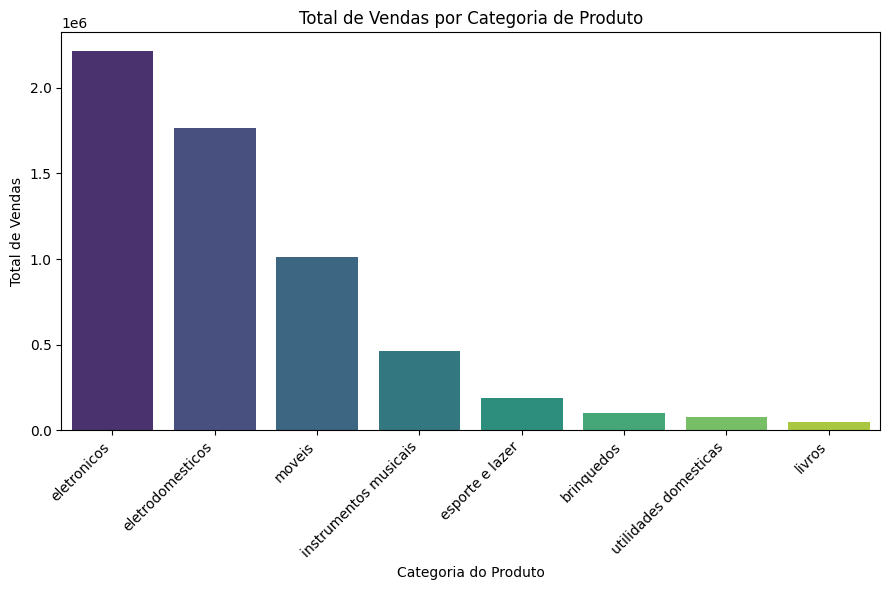

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.barplot(x=vendas_por_categoria.index, y=vendas_por_categoria.values, palette='viridis', hue=vendas_por_categoria.index, legend=False)
plt.title('Total de Vendas por Categoria de Produto')
plt.xlabel('Categoria do Produto')
plt.ylabel('Total de Vendas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Média de Avaliação das Lojas


In [34]:
media_avaliacao_por_loja = lojas_unidas.groupby('Loja')['Avaliação da compra'].mean().sort_values(ascending=False)
print("Média de Avaliação por Loja:")
print(media_avaliacao_por_loja)

Média de Avaliação por Loja:
Loja
loja_3    4.048326
loja_2    4.037304
loja_4    3.995759
loja_1    3.976685
Name: Avaliação da compra, dtype: float64


Vendas por Loja:
Loja
loja_1    1534509.12
loja_2    1488459.06
loja_3    1464025.03
loja_4    1384497.58
Name: Preço, dtype: float64


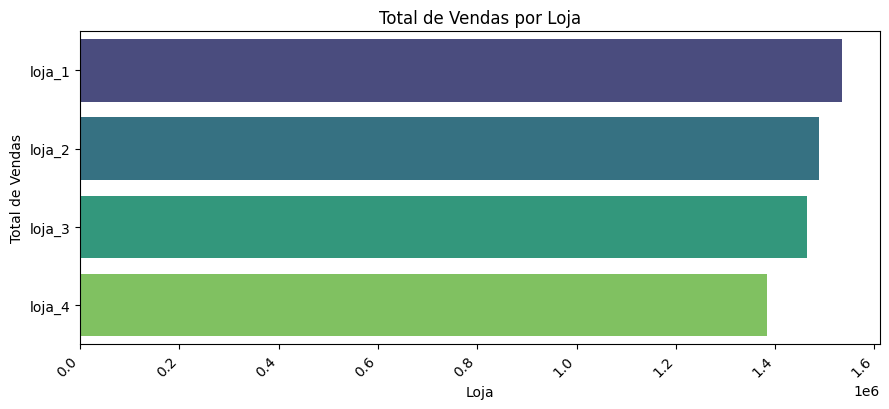

In [35]:
vendas_por_loja = lojas_unidas.groupby('Loja')['Preço'].sum().sort_values(ascending=False)
print("Vendas por Loja:")
print(vendas_por_loja)

plt.figure(figsize=(9, 4.2))
sns.barplot(x=vendas_por_loja.values, y=vendas_por_loja.index, palette='viridis', hue=vendas_por_loja.index, legend=False)
plt.title('Total de Vendas por Loja')
plt.xlabel('Loja')
plt.ylabel('Total de Vendas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Produtos Mais e Menos Vendidos

In [36]:
produtos_mais_vendidos = lojas_unidas.groupby('Produto')['Preço'].sum().sort_values(ascending=False)
print("Top 10 Produtos Mais Vendidos (em valor):")
print(produtos_mais_vendidos.head(10))

Top 10 Produtos Mais Vendidos (em valor):
Produto
TV Led UHD 4K         576652.70
Celular Plus X42      534735.14
Geladeira             513249.34
Smart TV              386963.12
Lavadora de roupas    323292.37
Lava louças           320715.58
Tablet ABXY           292016.76
Secadora de roupas    280317.31
Celular ABXY          210547.77
Bateria               197074.45
Name: Preço, dtype: float64


In [37]:
produtos_menos_vendidos = lojas_unidas.groupby('Produto')['Preço'].sum().sort_values(ascending=True)
print("Top 10 Produtos Menos Vendidos (em valor):")
print(produtos_menos_vendidos.head(10))

Top 10 Produtos Menos Vendidos (em valor):
Produto
Cubo mágico 8x8             3638.68
Corda de pular              4090.93
Dinossauro Rex              4150.53
Xadrez de madeira           6865.90
Jogo de copos               7445.28
Dashboards com Power BI     8557.88
Blocos de montar            9069.86
Copo térmico               11329.84
Faqueiro                   11413.85
Boneca bebê                11456.05
Name: Preço, dtype: float64


# 5. Frete Médio por Loja

In [38]:
frete_medio_por_loja = lojas_unidas.groupby('Loja')['Frete'].mean().sort_values(ascending=False)
print("Frete Médio por Loja:")
print(frete_medio_por_loja)

Frete Médio por Loja:
Loja
loja_1    34.691805
loja_2    33.621941
loja_3    33.074464
loja_4    31.278997
Name: Frete, dtype: float64


In [39]:
print(lojas_unidas.describe())

             Preço        Frete  Avaliação da compra  Quantidade de parcelas  \
count  9435.000000  9435.000000          9435.000000             9435.000000   
mean    622.309570    33.167002             4.014520                2.927398   
std     787.094508    41.973711             1.390518                2.802776   
min      10.070000     0.000000             1.000000                1.000000   
25%      73.610000     4.009423             3.000000                1.000000   
50%     295.350000    15.648481             5.000000                1.000000   
75%     884.405000    46.591030             5.000000                4.000000   
max    3969.380000   216.707633             5.000000               24.000000   

               lat          lon  Faturamento Total  
count  9435.000000  9435.000000        9435.000000  
mean    -20.534059   -47.171176         655.476572  
std       5.399153     4.177887         828.976991  
min     -30.170000   -70.550000          10.070000  
25%     -22.25

**Objetivo do Projeto**

Avaliar o desempenho das quatro lojas apresentadas, com base no conjunto oficial de dados do programa, utilizando as bibliotecas Pandas para análise de dados e Matplotlib para visualização gráfica. A partir dessa análise, será feita uma recomendação estratégica sobre qual loja deve ser vendida, considerando indicadores de performance relevantes.

**RELATÓRIO**

**Descrição das lojas_unidas:**

A função lojas_unidas.describe() fornece um resumo estatístico das colunas numéricas do DataFrame. Confira a análise de cada linha e coluna:

Colunas Analisadas (Preço, Frete, Avaliação da compra, Quantidade de parcelas, lat, lon, Faturamento Total):

- count: Indica o número de valores não nulos em cada coluna. Para todas as colunas, temos 9435 entradas, o que confirma que não há valores ausentes nessas colunas.

- mean (Média):

- Preço: A média dos preços dos produtos é de aproximadamente 622.31.
- Frete: O valor médio do frete é de cerca de 33.17.
- Avaliação da compra: A média das avaliações é de aproximadamente 4.01 (em uma escala de 1 a 5), indicando uma satisfação geral boa dos clientes.
- Quantidade de parcelas: Em média, as compras são parceladas em 2.93 vezes.
- lat / lon: As médias de latitude e longitude dão uma ideia do centro geográfico das compras, mas seus valores absolutos são menos intuitivos sem um mapa.
- Faturamento Total: O faturamento total médio (Preço + Frete) por transação é de cerca de 655.48.
- std (Desvio Padrão): Mede a dispersão dos dados em relação à média. Um valor alto indica que os dados estão mais espalhados.

- Preço: O desvio padrão de 787.09 é alto, sugerindo uma grande variação nos preços dos produtos.
- Frete: O desvio padrão de 41.97 também indica uma variação considerável nos valores de frete.
- Avaliação da compra: O desvio padrão de 1.39 é relativamente baixo, mostrando que a maioria das avaliações se agrupa perto da média (4.01).
- min (Mínimo): O menor valor observado em cada coluna.

- Preço: O produto mais barato custa 10.07.
- Frete: Há fretes de 0.00, o que pode indicar frete grátis ou algum erro de registro.
- Avaliação da compra: A avaliação mais baixa é 1.
25% (Primeiro Quartil): 25% dos dados estão abaixo deste valor.

- Preço: 25% dos produtos custam até 73.61.
50% (Mediana ou Segundo Quartil): Metade dos dados está abaixo deste valor. É menos sensível a valores extremos que a média.

- Preço: A mediana dos preços é 295.35.
75% (Terceiro Quartil): 75% dos dados estão abaixo deste valor.

- Preço: 75% dos produtos custam até 884.41.
max (Máximo): O maior valor observado em cada coluna.

- Preço: O produto mais caro custa 3969.38.
- Frete: O frete mais alto é 216.71.
- Avaliação da compra: A avaliação máxima é 5.

Em resumo, essa tabela nos dá uma visão rápida da distribuição, tendência central e dispersão das variáveis numéricas, revelando insights como a ampla faixa de preços, a satisfação geralmente alta dos clientes e a variabilidade nos custos de frete.


**Análise dos gráficos**


**Faturamento por loja:**

O gráfico de pizza gerado representa a proporção do faturamento total de cada loja em relação ao conjunto completo. Essa métrica é mais precisa que apenas o valor de venda, pois inclui o frete — o que pode impactar significativamente o desempenho financeiro.

Interpretação do Gráfico:
- loja_1 provavelmente mantém a maior fatia do faturamento total, reforçando sua liderança em vendas e ticket médio.
- loja_2 e loja_3 devem ocupar posições intermediárias, com participação relevante, mas abaixo da loja_1.
- loja_4 aparece com a menor fatia, confirmando seu desempenho inferior mesmo após incluir o frete.


**Vendas por categoria:**

- eletrônicos lideram com folga, representando mais de 30% do total de vendas.
- eletrodomésticos também apresenta grande desempenho, sugerindo boa aceitação e ticket médio elevado.
- móveis ocupam o terceiro lugar, com vendas significativas, mas bem abaixo das duas primeiras categorias.
- As categorias instrumentos musicais, esporte e lazer, brinquedos, utilidades domésticas e livros têm vendas muito inferiores, com destaque para livros, que representam menos de 1% do total.


**Vendas por loja:**

- loja_1 lidera com o maior volume de vendas, superando a segunda colocada por cerca de R$ 46 mil

- loja_2 e loja_3 apresentam uma pequena diferença, cerca de R$ 24 mil, indicando desempenho similar.

- loja_4 apresenta o menor total de vendas, com uma diferença de cerca de R$ 150 mil em relação à loja líder.

Visualização:
O gráfico de barras gerado com Matplotlib e Seaborn ilustra claramente essa hierarquia, destacando a superioridade da loja_1 em termos de faturamento.
No entanto, se o objetivo é vender uma loja com menor desempenho, a loja_4 é a candidata mais evidente. Porém, é importante considerar outros fatores antes de tomar uma decisão final, como:
- Margem de lucro por loja
- Custos operacionais
- Potencial de crescimento
- Localização e perfil de clientes.

Com base nos dados, após análises, a recomendação é Vender a loja_4, pois ela apresenta o menor faturamento, menor volume de vendas e está concentrada em categorias de baixo desempenho.







